In [12]:

import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
from collections import Counter
import ast

DATA_DIR = Path("../data")

df = pd.read_csv(DATA_DIR / "ted_talks_clean.csv")

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())
(df.info())


Dataset shape: (2550, 17)

Column names:
['comments', 'description', 'duration', 'event', 'film_date', 'languages', 'main_speaker', 'name', 'num_speaker', 'published_date', 'ratings', 'related_talks', 'speaker_occupation', 'tags', 'title', 'url', 'views']


,comments,description,duration,event,film_date,languages,main_speaker,name,num_speaker,published_date,ratings,related_talks,speaker_occupation,tags,title,url,views
0,4553,Sir Ken Robinson makes an entertaining and pro...,1164,TED2006,1140825600,60,Ken Robinson,Ken Robinson: Do schools kill creativity?,1,1151367060,"[{'id': 7, 'name': 'Funny', 'count': 19645}, {...","[{'id': 865, 'hero': 'https://pe.tedcdn.com/im...",Author/educator,"['children', 'creativity', 'culture', 'dance',...",Do schools kill creativity?,https://www.ted.com/talks/ken_robinson_says_sc...,47227110
1,265,With the same humor and humanity he exuded in ...,977,TED2006,1140825600,43,Al Gore,Al Gore: Averting the climate crisis,1,1151367060,"[{'id': 7, 'name': 'Funny', 'count': 544}, {'i...","[{'id': 243, 'hero': 'https://pe.tedcdn.com/im...",Climate advocate,"['alternative energy', 'cars', 'climate change...",Averting the climate crisis,https://www.ted.com/talks/al_gore_on_averting_...,3200520
2,124,New York Times columnist David Pogue takes aim...,1286,TED2006,1140739200,26,David Pogue,David Pogue: Simplicity sells,1,1151367060,"[{'id': 7, 'name': 'Funny', 'count': 964}, {'i...","[{'id': 1725, 'hero': 'https://pe.tedcdn.com/i...",Technology columnist,"['computers', 'entertainment', 'interface desi...",Simplicity sells,https://www.ted.com/talks/david_pogue_says_sim...,1636292
3,200,"In an emotionally charged talk, MacArthur-winn...",1116,TED2006,1140912000,35,Majora Carter,Majora Carter: Greening the ghetto,1,1151367060,"[{'id': 3, 'name': 'Courageous', 'count': 760}...","[{'id': 1041, 'hero': 'https://pe.tedcdn.com/i...",Activist for environmental justice,"['MacArthur grant', 'activism', 'business', 'c...",Greening the ghetto,https://www.ted.com/talks/majora_carter_s_tale...,1697550
4,593,You've never seen data presented like this. Wi...,1190,TED2006,1140566400,48,Hans Rosling,Hans Rosling: The best stats you've ever seen,1,1151440680,"[{'id': 9, 'name': 'Ingenious', 'count': 3202}...","[{'id': 2056, 'hero': 'https://pe.tedcdn.com/i...",Global health expert; data visionary,"['Africa', 'Asia', 'Google', 'demo', 'economic...",The best stats you've ever seen,https://www.ted.com/talks/hans_rosling_shows_t...,12005869


<class 'pandas.DataFrame'>
RangeIndex: 2550 entries, 0 to 2549
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   comments            2550 non-null   int64
 1   description         2550 non-null   str  
 2   duration            2550 non-null   int64
 3   event               2550 non-null   str  
 4   film_date           2550 non-null   int64
 5   languages           2550 non-null   int64
 6   main_speaker        2550 non-null   str  
 7   name                2550 non-null   str  
 8   num_speaker         2550 non-null   int64
 9   published_date      2550 non-null   int64
 10  ratings             2550 non-null   str  
 11  related_talks       2550 non-null   str  
 12  speaker_occupation  2550 non-null   str  
 13  tags                2550 non-null   str  
 14  title               2550 non-null   str  
 15  url                 2550 non-null   str  
 16  views               2550 non-null   int64
dtypes: int

In [13]:

print("Missing values by column:")
display(df.isnull().sum().sort_values(ascending=False))

print("Total missing cells:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate titles:", df["title"].duplicated().sum())
print("Empty titles:", df["title"].fillna("").str.strip().eq("").sum())


Missing values by column:


comments              0
description           0
duration              0
event                 0
film_date             0
languages             0
main_speaker          0
name                  0
num_speaker           0
published_date        0
ratings               0
related_talks         0
speaker_occupation    0
tags                  0
title                 0
url                   0
views                 0
dtype: int64

Total missing cells: 0
Duplicate rows: 0
Duplicate titles: 0
Empty titles: 0


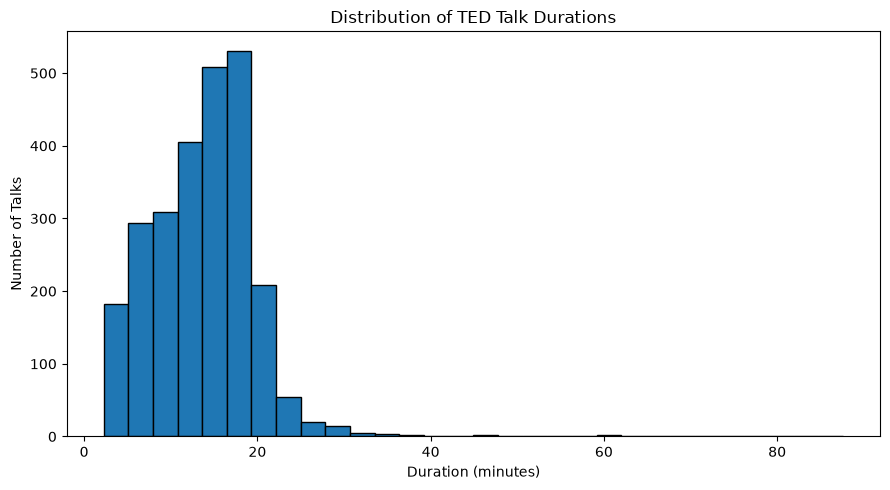

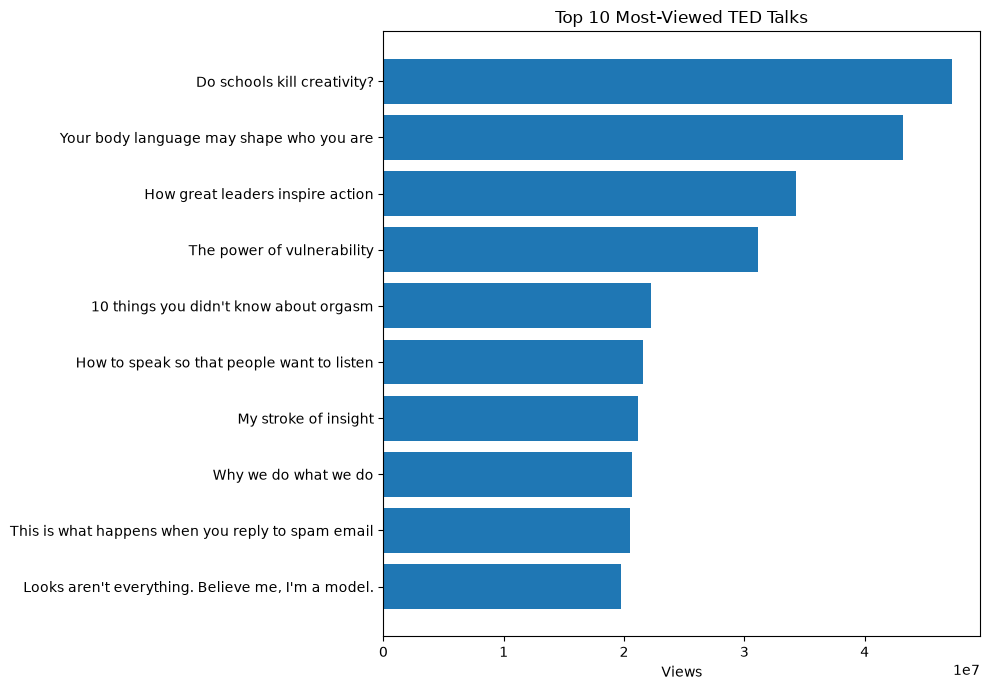

In [14]:

# Talk duration is stored in seconds
df["duration_minutes"] = df["duration"] / 60

plt.figure(figsize=(9, 5))
plt.hist(df["duration_minutes"], bins=30, edgecolor="black")
plt.title("Distribution of TED Talk Durations")
plt.xlabel("Duration (minutes)")
plt.ylabel("Number of Talks")
plt.tight_layout()
plt.show()

top10 = df.nlargest(10, "views").sort_values("views")

plt.figure(figsize=(10, 7))
plt.barh(top10["title"], top10["views"])
plt.title("Top 10 Most-Viewed TED Talks")
plt.xlabel("Views")
plt.tight_layout()
plt.show()


In [15]:

def parse_tags(value):
    try:
        parsed = ast.literal_eval(value)
        return parsed if isinstance(parsed, list) else []
    except (ValueError, SyntaxError, TypeError):
        return []

tags_by_talk = df["tags"].apply(parse_tags)
tag_counts = Counter(
    tag for tags in tags_by_talk for tag in tags
)

top_topics = pd.DataFrame(
    tag_counts.most_common(20),
    columns=["Topic", "Number of occurrences"]
)

display(top_topics)
print("Total unique topics:", len(tag_counts))


,Topic,Number of occurrences
0,technology,727
1,science,567
2,global issues,501
3,culture,486
4,TEDx,450
5,design,418
6,business,348
7,entertainment,299
8,health,236
9,innovation,229


Total unique topics: 416


In [16]:

transcript_path = DATA_DIR / "transcripts.csv"

if transcript_path.exists():
    transcripts = pd.read_csv(transcript_path)

    print("Transcript dataset shape:", transcripts.shape)
    print("\nTranscript columns:")
    print(transcripts.columns.tolist())

    print("\nMissing values:")
    display(transcripts.isnull().sum().sort_values(ascending=False))

    print("\nDuplicate rows:", transcripts.duplicated().sum())

    display(transcripts.head(3))

    # Show the length of the transcript text, if that column exists
    if "transcript" in transcripts.columns:
        transcripts["transcript_word_count"] = (
            transcripts["transcript"]
            .fillna("")
            .astype(str)
            .str.split()
            .str.len()
        )

        display(transcripts["transcript_word_count"].describe())

else:
    print("transcripts.csv was not found at:", transcript_path.resolve())
    print("Check that the file is inside your project's data folder.")


Transcript dataset shape: (2467, 2)

Transcript columns:
['transcript', 'url']

Missing values:


transcript    0
url           0
dtype: int64


Duplicate rows: 3


,transcript,url
0,Good morning. How are you?(Laughter)It's been ...,https://www.ted.com/talks/ken_robinson_says_sc...
1,"Thank you so much, Chris. And it's truly a gre...",https://www.ted.com/talks/al_gore_on_averting_...
2,"(Music: ""The Sound of Silence,"" Simon & Garfun...",https://www.ted.com/talks/david_pogue_says_sim...


count    2467.000000
mean     2040.279287
std       956.209248
min         1.000000
25%      1332.500000
50%      2028.000000
75%      2707.000000
max      9044.000000
Name: transcript_word_count, dtype: float64

In [17]:

if "transcripts" in globals():
    print("Possible shared identifiers:")

    for column in ["url", "title", "name", "main_speaker"]:
        in_main = column in df.columns
        in_transcripts = column in transcripts.columns

        if in_main and in_transcripts:
            main_values = set(df[column].dropna().astype(str))
            transcript_values = set(
                transcripts[column].dropna().astype(str)
            )

            overlap = len(main_values & transcript_values)

            print(
                f"{column}: "
                f"main unique={len(main_values)}, "
                f"transcript unique={len(transcript_values)}, "
                f"overlap={overlap}"
            )



Possible shared identifiers:
url: main unique=2550, transcript unique=2464, overlap=2464


In [18]:

# Check repeated transcript URLs
print("Repeated transcript URLs:")
print(transcripts["url"].duplicated().sum())

# Inspect the repeated URLs
print("\nRows with repeated URLs:")
display(
    transcripts[
        transcripts["url"].duplicated(keep=False)
    ].sort_values("url")
)

# Identify main-dataset talks without a matching transcript URL
main_urls = set(df["url"].dropna())
transcript_urls = set(transcripts["url"].dropna())

missing_urls = main_urls - transcript_urls

print("\nTalks without matching transcripts:", len(missing_urls))
display(
    df.loc[df["url"].isin(missing_urls), ["title", "main_speaker", "url"]]
    .head(10)
)


Repeated transcript URLs:
3

Rows with repeated URLs:


,transcript,url,transcript_word_count
1109,I'm going to tell you a little bit about my TE...,https://www.ted.com/talks/brene_brown_listenin...,2765
1116,I'm going to tell you a little bit about my TE...,https://www.ted.com/talks/brene_brown_listenin...,2765
1107,I have a question for you: Are you religious? ...,https://www.ted.com/talks/jonathan_haidt_human...,2796
1114,I have a question for you: Are you religious? ...,https://www.ted.com/talks/jonathan_haidt_human...,2796
1108,The recent debate over copyright laws like SOP...,https://www.ted.com/talks/rob_reid_the_8_billi...,678
1115,The recent debate over copyright laws like SOP...,https://www.ted.com/talks/rob_reid_the_8_billi...,678



Talks without matching transcripts: 86


,title,main_speaker,url
58,"A dance of ""Symbiosis""",Pilobolus,https://www.ted.com/talks/pilobolus_perform_sy...
115,"A string quartet plays ""Blue Room""",Ethel,https://www.ted.com/talks/ethel_performs_blue_...
135,"""Woza""",Vusi Mahlasela,https://www.ted.com/talks/vusi_mahlasela_s_enc...
209,"""M'Bifo""",Rokia Traore,https://www.ted.com/talks/rokia_traore_sings_m...
237,"""Kounandi""",Rokia Traore,https://www.ted.com/talks/rokia_traore_sings_k...
249,"A performance with breath, music, passion",Sxip Shirey + Rachelle Garniez,https://www.ted.com/talks/sxip_shirey_at_the_b...
399,Piano jazz that rocks,Eric Lewis,https://www.ted.com/talks/eric_lewis_strikes_c...
446,Chaos and harmony on piano,Eric Lewis,https://www.ted.com/talks/eric_lewis_plays_cha...
474,An electrifying organ performance,Qi Zhang,https://www.ted.com/talks/qi_zhang_s_electrify...
512,Hypnotic South Asian improv music,Vishal Vaid,https://www.ted.com/talks/vishal_vaid_s_hypnot...


# TED Talks Dataset — EDA Findings

## Dataset overview
- The cleaned dataset contains 2,550 TED Talks and 17 columns.
- Six missing speaker occupations were filled with "Unknown".
- The data-quality check found no duplicate rows or duplicate titles.

## Popularity
- "Do schools kill creativity?" by Ken Robinson is the most-viewed talk in this dataset.
- Views indicate popularity, but popularity alone does not mean a talk is relevant to every user.

## Duration
- The average duration is approximately 13.78 minutes.
- The median duration is approximately 14.13 minutes.
- Talk durations vary considerably.

## Topics
- The dataset contains 416 unique tags.
- Technology, science, global issues, and culture are among the most frequent tags.
- Each talk can have multiple tags.

## Relevance to the project
Titles, descriptions, and tags provide useful text for building a content-based recommendation system. Transcripts may provide richer information after their quality and matching identifiers have been checked.

## Transcript dataset findings
- The transcript dataset contains 2,467 rows and 2 columns: `transcript` and `url`.
- No missing values were found in either column.
- Three transcript URLs are repeated. These should be checked before removing duplicates.
- There are 2,464 unique transcript URLs that match URLs in the main dataset.
- Eighty-six talks in the main dataset do not have a matching transcript URL.
- Some unmatched examples are musical performances. The transcript dataset should therefore be treated as an optional source of additional text, rather than assuming every talk has a transcript.